##Data Visualization With Seaborn

#Session 2

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

1.<p>Generate 300 orders for a fictional Ahmedabad tiffin service in a notebook named 'tiffin_categorical.ipynb', with order_id, area (Satellite, Bopal, Maninagar, Naranpura or Vastrapur), meal_type (Veg 50%, Jain 20%, Diet 30%), plan_type (Trial, Weekly or Monthly), quantity (1 to 4) and amount_inr (quantity x 90 for Veg, x 100 for Jain, x 140 for Diet). Use `np.random.seed(42)`, save it as 'tiffin_orders.csv' and draw `sns.countplot` of meal_type with `order=['Veg', 'Jain', 'Diet']`.</p>

   order_id       area meal_type plan_type  quantity  amount_inr
0         1  Naranpura      Diet    Weekly         1         140
1         2  Vastrapur       Veg   Monthly         2         180
2         3  Maninagar      Jain   Monthly         4         400
3         4  Vastrapur      Jain    Weekly         4         400
4         5  Vastrapur      Diet    Weekly         3         420
Dataset Shape: (300, 6)
CSV file saved successfully!


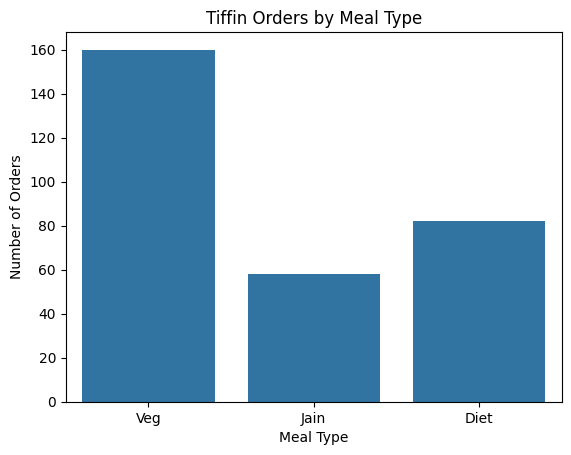

In [ ]:
np.random.seed(42)  #same random sequence generate
order_id = np.arange(1, 301) #sequence generate
area = np.random.choice(['Satellite', 'Bopal', 'Maninagar', 'Naranpura', 'Vastrapur'],size=300) #random values select

#Generate Meal Type
meal_type = np.random.choice(['Veg', 'Jain', 'Diet'],size=300,p=[0.50, 0.20, 0.30])

#Generate Plan Type
plan_type = np.random.choice(['Trial', 'Weekly', 'Monthly'],size=300)

#Generate Quantity    #random integer generate
quantity = np.random.randint(1, 5, size=300)

#Calculate Amount
price = {'Veg': 90,'Jain': 100,'Diet': 140}

amount_inr = [
    quantity[i] * price[meal_type[i]]
    for i in range(300)
]

df = pd.DataFrame({
    'order_id': order_id,
    'area': area,
    'meal_type': meal_type,
    'plan_type': plan_type,
    'quantity': quantity,
    'amount_inr': amount_inr
})
print(df.head())
print("Dataset Shape:", df.shape)

#Save CSV File
df.to_csv('tiffin_orders.csv', index=False)
print("CSV file saved successfully!")

#Draw Countplot
sns.countplot(data=df,x='meal_type',order=['Veg', 'Jain', 'Diet'])
plt.title('Tiffin Orders by Meal Type')
plt.xlabel('Meal Type')
plt.ylabel('Number of Orders')
plt.show()


2.<p>Plot the number of orders per area with `sns.countplot`, sorted from the busiest area to the quietest, with area on the y-axis and `hue='plan_type'`. Save the chart as 'tiffin_area_plans.png'. Hint: pass `order=df['area'].value_counts().index` to sort the bars.</p>

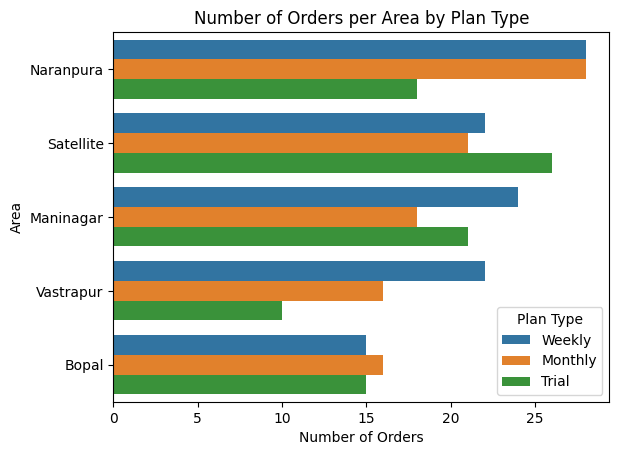

In [ ]:
sns.countplot(
    data=df,
    y='area',
    order=df['area'].value_counts().index,
    hue='plan_type'
)
plt.title('Number of Orders per Area by Plan Type')
plt.xlabel('Number of Orders')
plt.ylabel('Area')
plt.legend(title='Plan Type')

plt.savefig('tiffin_area_plans.png', dpi=150, bbox_inches='tight')
plt.show()


3.<p>Build a figure with two side-by-side barplots of amount_inr per meal_type: the left one shows the mean with the default error bars, and the right one shows the total using `estimator='sum'` with the error bars removed. Save the figure as 'tiffin_mean_vs_sum.png'. Hint: Use `errorbar=None` to remove the intervals (older seaborn versions used `ci=None`).</p>

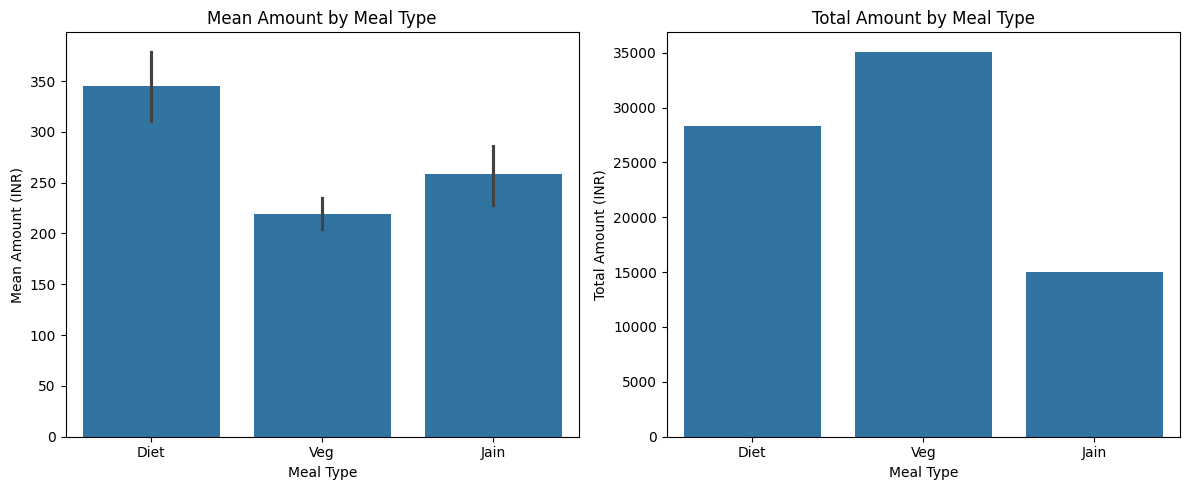

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
# Left Plot: Mean Amount
sns.barplot(data=df,x='meal_type',y='amount_inr',ax=ax[0])
ax[0].set_title('Mean Amount by Meal Type')
ax[0].set_xlabel('Meal Type')
ax[0].set_ylabel('Mean Amount (INR)')


# Right Plot: Total Amount
sns.barplot(data=df,x='meal_type',y='amount_inr',estimator='sum',errorbar=None,ax=ax[1])
ax[1].set_title('Total Amount by Meal Type')
ax[1].set_xlabel('Meal Type')
ax[1].set_ylabel('Total Amount (INR)')

plt.tight_layout()
plt.savefig('tiffin_mean_vs_sum.png', dpi=150, bbox_inches='tight')
plt.show()


4.<p>Finish the notebook with one barplot of total revenue (sum of amount_inr) per area, sorted highest first, without error bars, with the rupee value written on top of every bar and a clear title. Save it as 'tiffin_revenue_by_area.png', run Restart & Run All and submit the notebook, the CSV and the PNG files. Hint: `ax.bar_label(ax.containers[0])` writes the values on the bars.</p>

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df,
    x='area',
    y='amount_inr',
    estimator='sum',
    errorbar=None,
    order=df.groupby('area')['amount_inr'].sum().sort_values(ascending=False).index
)
ax.bar_label(ax.containers[0], fmt='₹%.0f', padding=3)
plt.title('Total Tiffin Revenue by Area', fontsize=14)
plt.xlabel('Area')
plt.ylabel('Total Revenue (INR)')
plt.tight_layout()
plt.savefig('tiffin_revenue_by_area.png', dpi=150, bbox_inches='tight')
plt.show()
